# 01 · Preprocessing — Wu et al. 2020 Acute Myeloid Leukemia (malignant compartment)

Isolate malignant AML blasts, threshold thin samples by a **data-driven multiplicative gap**,
integrate patients (Harmony on `sample`), embed, strip detached specks, and read **Gate 1**
(sample-mixing + manifold continuity) off the regenerated embedding plus a per-neighbourhood metric
(iLISI) across an integration-strength sweep — never a scalar alone.

Wu 2020 profiles AML bone marrow by **Microwell-seq**, delivered here as four count matrices
(`Group1..4`) that we load leaf-by-leaf and concatenate exactly as `merge.py` does. After selecting
the publication's `Malignant` blasts across **38 patients (~97k cells)**, AML is strongly
patient-private (each clone carries its own driver/CNV background), so raw segregation is expected and
strong Harmony integration is required; the blasts are a **uniformly low-cycling** population — no
cell-cycle compartment confounds the axis. Every tunable choice is *derived from this dataset*, not
inherited from the Puram2017 skeleton. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad, scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 0; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Wu2020_Hematologic-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

# input folder = dataset name minus the '-2' re-analysis suffix
raw_name = 'Data_' + name.replace('-2','')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Wu2020_Hematologic-2 | category: Hematologic | raw: Data_Wu2020_Hematologic


### Load malignant compartment — leaf-by-leaf, then concatenate
The loader reads one leaf matrix directory; Wu 2020 nests four (`Group1..4`), so we walk to the leaves
and `ad.concat(join='outer')` exactly as `merge.py` prescribes. The loader auto-detects UMI counts
(`Exp_data_UMIcounts*.mtx`), normalizes total + `log1p`, and carries the publication `cell_type`; we
keep its malignant call (`celltype == 'Malignant'`) and drop the normal marrow compartment
(neutrophil/monocyte/erythroid/T/B/etc.).

In [3]:
leaves = sorted(dp for dp,sd,_ in os.walk(pth_in) if len(sd)==0)
print('leaf matrix dirs:', [os.path.basename(l) for l in leaves])
ad_dict = {os.path.basename(l): load_CCCA_adata(l, verbose=False) for l in leaves}
adata = ad.concat(ad_dict, join='outer', merge='same', label='group')
adata.obs_names_make_unique()
print('full atlas:', adata.shape)
print('cell types:', adata.obs['celltype'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

leaf matrix dirs: ['Group1', 'Group2', 'Group3', 'Group4']
full atlas: (194571, 13915)
cell types: {'Malignant': 97030, 'Neutrophil': 39277, 'Monocyte': 17267, 'Erythroid': 9877, 'Proliferating_Cell': 8073, 'Promonocyte': 7078, 'T_cell': 5050, 'Basophil': 4065, 'Erythroblast': 3382, 'B_cell': 3177, 'AML_progenitor_cell': 295}
malignant: (97030, 13915) | samples: 38
expression: X max 5.76 (log1p of normalize_total UMI counts)


### Sample thresholding — derived by multiplicative gap-finding
Sort per-sample malignant counts; a *dominant* multiplicative cliff (top gap far larger than the next,
falling into the spillover regime) would set a geometric-mean threshold. Here the distribution is
smooth (largest ratio 4.26 at 417->98, but top/second only 1.35 — no dominant cliff), so the premise
is not met and we fall back to the **>=100-cell floor**, dropping the two thinnest samples (P18=98,
P13=31). 36/38 samples retained.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', n.values.astype(int).tolist())
print(f'largest multiplicative gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print(f'{"dominant cliff -> geometric-mean" if dominant else "no dominant cliff -> floor"} threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [8164, 7340, 6582, 4826, 4695, 4528, 4527, 4201, 4011, 3914, 3484, 3098, 3074, 3031, 2893, 2822, 2336, 2315, 2219, 2202, 1984, 1657, 1630, 1471, 1344, 1234, 1194, 1142, 834, 751, 679, 635, 588, 543, 536, 417, 98, 31]
largest multiplicative gap 417->98 (ratio 4.26); top/second = 1.35; dominant cliff = False
no dominant cliff -> floor threshold = 100
kept 36/38 samples (min per-sample 417) -> 96901 cells


### Overdispersion, PCA, Harmony integration, embedding
Overdispersed-gene selection (scFates GAM), PCA (**no `sc.pp.scale`** — it is absent from the reference
protocol and has produced false NO-GOs), then Harmony on `sample`. `theta` is picked from an
integration-strength sweep read on a per-neighbourhood metric (**iLISI** = effective #samples in each
cell's neighbourhood): pre-Harmony iLISI is ~1 (fully patient-segregated, as expected for private AML
clones), rising to a plateau by `theta=10` and declining under over-integration (`theta>=20`). We take
`theta=10`. PC count is set to **30** — squarely in the robust 20-40 range (not the under-powered floor
that forced false segregation on earlier runs).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50, random_state=SEED)

def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
NPC = 30
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:NPC], adata.obs['sample'].values))
sweep = {}
for th in [5, 10, 20, 30]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    sweep[th] = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:NPC], adata.obs['sample'].values))
nb_s = adata.obs['sample'].nunique()
print(f'iLISI median (n_pcs={NPC}) | pre-Harmony {il_pre:.2f} of {nb_s} samples | sweep', {k: round(v,2) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus by theta=10; theta>=20 over-integrates)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 443 over-dispersed features (0:00:03) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 443
iLISI median (n_pcs=30) | pre-Harmony 1.00 of 36 samples | sweep {5: np.float64(10.05), 10: np.float64(10.23), 20: np.float64(9.04), 30: np.float64(8.79)}
selected theta = 10 (mixing plateaus by theta=10; theta>=20 over-integrates)


### Island removal — UMAP radius graph, keep the largest component
Build a radius graph at 6x the median nearest-neighbour distance and keep the largest connected
component. Only tiny detached specks are stripped; the manifold is a single dense mass.

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached specks')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells')

removed 26 cells in 23 detached specks
after island removal: 96875 cells


### Cell cycle + single-lobe check
Score the cell cycle and cluster coarsely (Leiden 0.15). The whole manifold is a **single uniformly
low-cycling body** — no cycling compartment to scope out (contrast Kurten's cycling lobe), so the full
malignant manifold is carried forward.

In [7]:
s_genes = ('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split()
g2m_genes = ('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split()
sc.tl.score_genes_cell_cycle(adata, [g for g in s_genes if g in adata.var_names],
                             [g for g in g2m_genes if g in adata.var_names])
adata.obs['cc_score'] = np.maximum(adata.obs['S_score'], adata.obs['G2M_score'])
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED, flavor='igraph', n_iterations=2)
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cc_score per lobe:', adata.obs.groupby('lobe', observed=True)['cc_score'].mean().round(3).to_dict())
adata.obs['compartment'] = pd.Categorical(['Body']*adata.n_obs)   # single low-cycling body
print('overall cc_score mean %.3f -> single low-cycling body, whole manifold kept' % adata.obs['cc_score'].mean())

lobe sizes: {'0': 96875}
cc_score per lobe: {'0': 0.007}
overall cc_score mean 0.007 -> single low-cycling body, whole manifold kept


### Module signatures (raw + graph-smoothed) and house linear layout
`score_genes` for Gast/pSom/Crest against the union control pool (raw per-cell scores are the honest
deliverable readout). A 3-step kNN-connectivity smoothing (`*_sm`) is stored for reading geography/
correlations robustly. We also store a PCA-rotated linear layout `X_umap_lin` (origin pole on the left)
for the house `(3.5,1.5)` panels.

In [8]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=l, ctrl_as_ref=False, gene_pool=list(g_ref), random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
origin_score = (S[:,0] + S[:,1]) - S[:,2]
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max()/c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print('global raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed module geography:')
for a,b in [('Gast_sm','pSom_sm'),('Gast_sm','Crest_sm'),('pSom_sm','Crest_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
print(f'manifold aspect (max/min std): {aspect:.2f}')

Gast: 41/81 genes present
pSom: 47/98 genes present
Crest: 72/104 genes present
global raw module means (honest readout): {'Gast': 0.0019, 'pSom': 0.0066, 'Crest': -0.0042}
smoothed module geography:
  Gast_sm vs pSom_sm: r = -0.64
  Gast_sm vs Crest_sm: r = -0.63
  pSom_sm vs Crest_sm: r = +0.09
manifold aspect (max/min std): 1.39


### Gate 1 — mixing + continuity read off the regenerated embedding
iLISI rises from ~1 (segregated) pre-Harmony to a high plateau post-Harmony (many effective samples in
each neighbourhood), and the kNN graph is a **single connected component** — the manifold is both
sample-integrated and continuous. **Gate 1 = GO.**

In [9]:
def _ilisi2(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre  = np.median(_ilisi2(adata.obsm['X_pca'][:,:NPC], adata.obs['sample'].values))
il_post = np.median(_ilisi2(adata.obsm['X_pca_harmony'][:,:NPC], adata.obs['sample'].values))
ncomp_knn,_ = connected_components(adata.obsp['connectivities'], directed=False)
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {nb_s} samples')
print(f'kNN graph connected components: {ncomp_knn} (=1 -> one continuous manifold)')
print('Gate 1: samples intermix per-neighbourhood on one continuous, low-cycling manifold -> GO')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 10.23 of 36 samples
kNN graph connected components: 1 (=1 -> one continuous manifold)
Gate 1: samples intermix per-neighbourhood on one continuous, low-cycling manifold -> GO


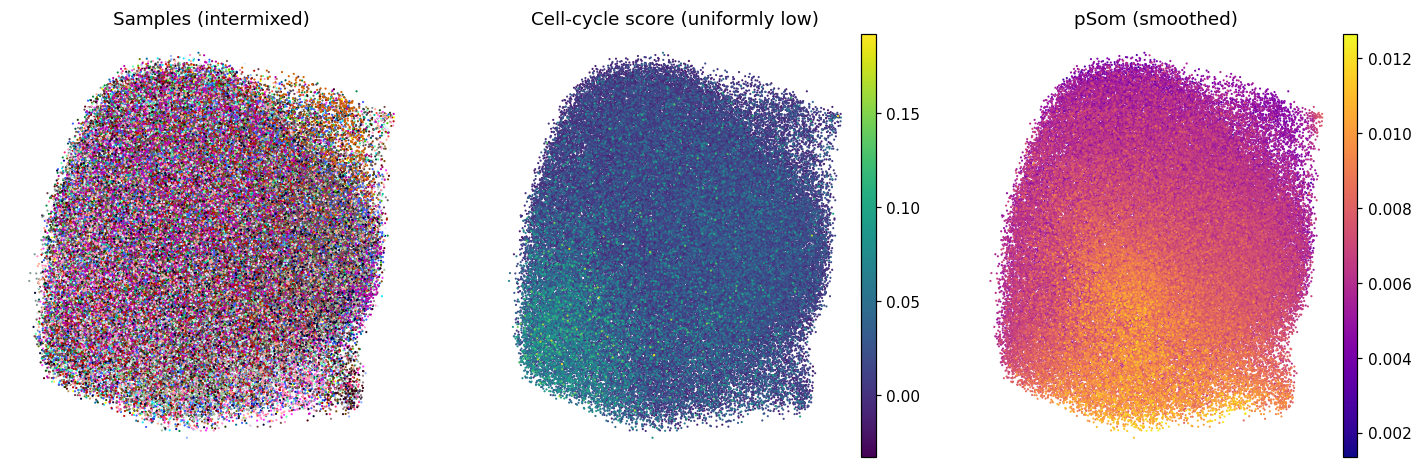

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16,5))
sc.pl.umap(adata, color='sample', size=8, frameon=False, show=False, ax=ax[0], title='Samples (intermixed)', legend_loc=None)
sc.pl.umap(adata, color='cc_score', cmap='viridis', size=8, frameon=False, show=False, ax=ax[1], title='Cell-cycle score (uniformly low)')
sc.pl.umap(adata, color='pSom_sm', cmap='plasma', size=8, frameon=False, show=False, ax=ax[2], title='pSom (smoothed)')
plt.show()

### Persist `processed.h5ad` and the `samples.pdf` deliverable

In [11]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','group','phase'}
for cix in adata.obs.columns:
    if cix in protect:
        adata.obs[cix] = adata.obs[cix].astype(str).astype('category'); continue
    col = adata.obs[cix]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[cix] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (96875, 13907)


saved samples.pdf | cells: 96875


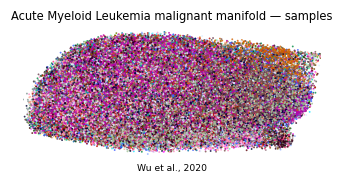

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=6, alpha=.8, frameon=False, show=False, ax=ax, legend_loc=None)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Acute Myeloid Leukemia malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Wu et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])